# Module 7 — Task 2: Is the prediction worth money?

**Task 2 (brief, verbatim):**
> **ML task 2 — model probability into trading signal.** Does the prediction generate enough economic value? Can we generate some trading signal and backtest.

**And the Head of Trading's question (brief, verbatim):** *"Can ML use limit-order-book information to predict short-horizon price movements **and improve order execution**?"*

**In plain words:** Task 1's model says, every moment, how likely the price is to rise, fall or not move in the next tenth of a second. Two separate tests ask whether that's worth money (decision M7-12):
- **Test 1 — trading on the signal:** buy when a rise is likely, sell when a fall is likely, and get out a tenth of a second later. Every round trip pays the bid–ask gap and India's trading charges.
- **Test 2 — timing orders the desk must place anyway:** when the desk has to buy, wait a moment if the model expects a fall (and the reverse for a sell). The charges are paid either way, so only the price saved counts.
- The two results form **one recommendation** for the Head of Trading.

**Terms:**
- **The lean (the signal):** the model's chance of a rise − its chance of a fall. Example: 70% rise, 20% fall → lean +0.50 → buy.
- **Expected gain:** Task 1 found the move a trade catches grows in step with the lean (about 7 bps × the lean). So each moment's expected gain = that slope × |lean|.
- **This moment's cost:** that moment's own spread + 3.5 bps of charges. Test 1 trades only when the expected gain beats it (revised decision M7-13).
- **bp (basis point):** 0.01%. Money is shown **per ₹1 crore traded**: 1 bp = ₹1,000. ₹1 crore is a measuring unit, not a trade size.
- **Spread cost:** buying at the sellers' price and selling at the buyers' price costs the bid–ask gap once per round trip (about 1.1 bps = ₹1,100).
- **Charges (decision M7-06):** about **3.5 bps = ₹3,500** per ₹1 crore round trip: securities transaction tax 0.025% on the sale (2.5 bps), exchange charges about 0.003% each way (0.6), stamp duty 0.003% on the purchase (0.3), SEBI fee and GST (0.1).

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | Task 1's predictions |
| 2 | Test 1: the cost-aware trading rule, set on the tuning days (M7-13, revised after Task 1's review) |
| 3 | Test 1 on the test days: profit after costs, by day and stock, 95% range, luck check, nearby margins, cost check (M7-15) |
| 4 | Test 2: timing the desk's orders (M7-14) |
| 5 | The recommendation |
| 6 | What the results say |
| 7 | Save the outputs |

## 0. Setup
Works locally and in Google Colab. Takes under a minute. Needs Task 1's outputs.

In [1]:
import sys
import json
import warnings
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_07_hft"
IN_DIR = MODULE_DIR / "outputs" / "task1"
OUT_DIR = MODULE_DIR / "outputs" / "task2"
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from m07_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, GAIN, LOSS
apply_style()
plt.close("all")

SEED = 42
CHARGES_BPS = 3.5               # Indian intraday charges per round trip (decision M7-06)
RUPEES_PER_BP = 1000            # on ₹1 crore traded
CUTOFFS = np.round(np.arange(0.40, 0.86, 0.05), 2)          # the old fixed-cut-off rule, kept for comparison
MARGINS = [-0.5, -0.25, 0.0, 0.25, 0.5, 0.75, 1.0, 1.5]       # extra bps the expected gain must beat the cost by
N_LUCK = 1000                   # random runs for each luck check
DAYS_A_YEAR = 261               # every weekday, as in the data (Module 6, decision M6-03)
DESK_CRORE_A_DAY = 100          # illustrative desk volume: ₹100 crore of orders a day (Module 9 scales it, M7-14)
pd.set_option("display.width", 220, "display.max_columns", 30)


def save_table(table: pd.DataFrame, name: str) -> None:
    table.to_csv(OUT_DIR / f"{name}.csv", index=False)


def save_chart(fig, name: str) -> None:
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def rupees(bps):
    """bps on ₹1 crore → ₹."""
    return bps * RUPEES_PER_BP


print("Reads from:", IN_DIR.relative_to(PROJECT_ROOT).as_posix()); print("Outputs go to:", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Reads from: module_07_hft/outputs/task1
Outputs go to: module_07_hft/outputs/task2


## 1. Task 1's predictions

For every tuning-day (15–17) and test-day (18–20) moment: the chosen model's chances, its lean, the spread, and the actual move 0.1 s later (used **only to score** the result, never to decide).

In [2]:
pred = pd.read_csv(IN_DIR / "FINAL_M7_T1_direction_predictions.csv")
K1 = json.loads((IN_DIR / "key_numbers.json").read_text(encoding="utf-8"))
SLOPE = K1["task2_review"]["slope_bps_per_lean"]          # Task 1 step 7: move caught ≈ SLOPE × |lean| (tuning days)
MODEL = pred["Model used"].iloc[0]
LEAN = "Lean (chance of UP − chance of DOWN)"
tune, test = pred[pred.Set == "Tuning day"].copy(), pred[pred.Set == "Test day"].copy()
print(f"Model from Task 1: {MODEL}; tuning moments {len(tune):,}, test moments {len(test):,}")
print(f"From Task 1's review (step 7): expected move caught ≈ {SLOPE:.2f} bps × |lean|; spreads are wider when the model is most confident "
      f"({K1['task2_review']['spread_most_vs_least_confident'][0]:.2f} vs {K1['task2_review']['spread_most_vs_least_confident'][1]:.2f} bps)")
print(f"Typical spread {test['Spread (bps)'].median():.2f} bps (₹{rupees(test['Spread (bps)'].median()):,.0f} per ₹1 crore); "
      f"typical move {test['Actual move (bps)'].abs().median():.2f} bps (₹{rupees(test['Actual move (bps)'].abs().median()):,.0f})")

Model from Task 1: Logistic regression; tuning moments 18,070, test moments 17,876
From Task 1's review (step 7): expected move caught ≈ 7.09 bps × |lean|; spreads are wider when the model is most confident (1.77 vs 1.10 bps)
Typical spread 1.14 bps (₹1,136 per ₹1 crore); typical move 3.88 bps (₹3,875)


## 2. Test 1: the cost-aware trading rule, set on the tuning days (decision M7-13, revised)

**Why the rule changed:** the first rule traded whenever the model's lean was beyond one fixed cut-off (0.70). Task 1's review (its step 7) found that the model is most confident exactly where spreads are widest, so a fixed cut-off trades where costs are highest. Because the percentages are honest and the move caught grows in step with the lean, each moment's gain can be estimated and compared with **that moment's own cost**:

```text
Expected gain   = slope × |lean|  (slope ≈ 7.1 bps, from Task 1's step 7 on the tuning days)
This moment's cost = this moment's spread + 3.5 bps of charges
Trade if  expected gain − this moment's cost  >  margin               (buy if lean > 0, sell if < 0)
Example: lean 0.6, spread 0.8 bps → expected 4.25; cost 4.3 → no trade.  Spread 0.5 → cost 4.0 → trade (margin 0)
```

The **margin** (how much the expected gain must beat the cost by) with the most total profit on the tuning days is used unchanged on the test days. The old fixed cut-off rule is set the same way and shown alongside for comparison.

```text
Move captured  = +move if bought, −move if sold                     (bps)
After spread   = move captured − spread;   After charges = after spread − 3.5 bps;   × ₹1,000 = ₹ per ₹1 crore
```

In [3]:
def score_trades(x: pd.DataFrame, cost_bps: float = CHARGES_BPS) -> pd.DataFrame:
    """Side, move captured and the result after each cost, for the moments in x."""
    x = x.copy()
    x["Side"] = np.where(x[LEAN] > 0, "Buy", "Sell")
    x["Captured (bps)"] = np.sign(x[LEAN]) * x["Actual move (bps)"]
    x["After spread (bps)"] = x["Captured (bps)"] - x["Spread (bps)"]
    x["After charges (bps)"] = x["After spread (bps)"] - cost_bps
    x["Outcome"] = np.where(x.Actual == "NO_MOVE", "No move", np.where((x.Side == "Buy") == (x.Actual == "UP"), "Right way", "Wrong way"))
    return x


def expected_edge(part: pd.DataFrame, cost_bps: float = CHARGES_BPS) -> pd.Series:
    """Expected gain − this moment's cost, in bps."""
    return SLOPE * part[LEAN].abs() - part["Spread (bps)"] - cost_bps


def cost_aware(part: pd.DataFrame, margin: float, rule_cost: float = CHARGES_BPS, real_cost: float = CHARGES_BPS) -> pd.DataFrame:
    """Trades chosen assuming rule_cost of charges, scored at real_cost."""
    return score_trades(part[expected_edge(part, rule_cost) > margin], real_cost)


def fixed_cutoff(part: pd.DataFrame, cut: float) -> pd.DataFrame:
    """The old rule: trade whenever |lean| > cut."""
    return score_trades(part[part[LEAN].abs() > cut])


def summary_row(label, x, n_moments):
    return {"Rule": label, "Trades": len(x), "Share of moments": len(x) / n_moments,
            "Net per trade (₹ per ₹1 crore)": rupees(x["After charges (bps)"].mean()) if len(x) else np.nan,
            "Net total (₹ lakh, ₹1 crore a trade)": rupees(x["After charges (bps)"].sum()) / 1e5,
            "Average spread paid (₹)": rupees(x["Spread (bps)"].mean()) if len(x) else np.nan}


sweep = pd.DataFrame([summary_row(f"Cost-aware, margin {m:+.2f} bp", cost_aware(tune, m), len(tune)) | {"Margin": m} for m in MARGINS])
MARGIN = float(sweep.loc[sweep["Net total (₹ lakh, ₹1 crore a trade)"].idxmax(), "Margin"])
old = pd.DataFrame([summary_row(f"Fixed cut-off {c:.2f}", fixed_cutoff(tune, c), len(tune)) | {"Cut-off": c} for c in CUTOFFS])
CUT = float(old.loc[old["Net total (₹ lakh, ₹1 crore a trade)"].idxmax(), "Cut-off"])
FMT_T = {"Share of moments": "{:.1%}", "Net per trade (₹ per ₹1 crore)": "₹{:+,.0f}", "Net total (₹ lakh, ₹1 crore a trade)": "₹{:+.1f}",
         "Average spread paid (₹)": "₹{:,.0f}"}
print(f"Tuning days. Cost-aware rule: chosen margin {MARGIN:+.2f} bp (most total profit)")
display(sweep.drop(columns="Margin").style.format(FMT_T, na_rep="—").hide(axis="index"))
print(f"For comparison, the old fixed cut-off rule: best cut-off {CUT} on the tuning days")
display(old.drop(columns="Cut-off").style.format(FMT_T, na_rep="—").hide(axis="index"))

Tuning days. Cost-aware rule: chosen margin +0.00 bp (most total profit)


Rule,Trades,Share of moments,Net per trade (₹ per ₹1 crore),"Net total (₹ lakh, ₹1 crore a trade)",Average spread paid (₹)
"Cost-aware, margin -0.50 bp",2942,16.3%,₹+372,₹+10.9,₹881
"Cost-aware, margin -0.25 bp",2153,11.9%,₹+523,₹+11.3,₹848
"Cost-aware, margin +0.00 bp",1479,8.2%,₹+799,₹+11.8,₹804
"Cost-aware, margin +0.25 bp",958,5.3%,"₹+1,049",₹+10.0,₹758
"Cost-aware, margin +0.50 bp",581,3.2%,"₹+1,260",₹+7.3,₹726
"Cost-aware, margin +0.75 bp",324,1.8%,"₹+1,411",₹+4.6,₹708
"Cost-aware, margin +1.00 bp",139,0.8%,"₹+1,871",₹+2.6,₹704
"Cost-aware, margin +1.50 bp",9,0.0%,₹+944,₹+0.1,₹675


For comparison, the old fixed cut-off rule: best cut-off 0.7 on the tuning days


Rule,Trades,Share of moments,Net per trade (₹ per ₹1 crore),"Net total (₹ lakh, ₹1 crore a trade)",Average spread paid (₹)
Fixed cut-off 0.40,8570,47.4%,₹-959,₹-82.1,"₹1,475"
Fixed cut-off 0.45,7096,39.3%,₹-740,₹-52.5,"₹1,495"
Fixed cut-off 0.50,5535,30.6%,₹-505,₹-27.9,"₹1,517"
Fixed cut-off 0.55,4052,22.4%,₹-259,₹-10.5,"₹1,552"
Fixed cut-off 0.60,2656,14.7%,₹-55,₹-1.5,"₹1,657"
Fixed cut-off 0.65,1592,8.8%,₹+222,₹+3.5,"₹1,819"
Fixed cut-off 0.70,867,4.8%,₹+455,₹+3.9,"₹2,139"
Fixed cut-off 0.75,460,2.5%,₹+624,₹+2.9,"₹2,486"
Fixed cut-off 0.80,198,1.1%,₹+772,₹+1.5,"₹2,953"
Fixed cut-off 0.85,22,0.1%,"₹+1,008",₹+0.2,"₹2,987"


## 3. Test 1 on the test days (decision M7-15)

**Enough economic value** = net profit above zero after all costs, **beyond luck** (p < 0.05), and **positive on most test days**. Also shown, as in the other modules: the **95% range** of the total (resampling the trades) and the result **by stock**.

**Luck check:** 1,000 runs that each trade the **same number** of random test moments in a random direction, with the same costs. p = (runs doing at least as well + 1) ÷ 1,001.

Test days, cost-aware rule (margin +0.00 bp): 1,473 trades (8.2% of moments)


Step,Per trade (bps),Per trade (₹ per ₹1 crore),Total over 3 test days (₹ lakh)
Before costs (move captured),+4.99,"₹+4,994",₹+73.6
After the bid–ask spread,+4.20,"₹+4,200",₹+61.9
After spread and charges,+0.70,₹+700,₹+10.3


How the trades landed: Right way 78% (avg ₹+6,982 before costs), Wrong way 12% (avg ₹-3,793 before costs), No move 11% (avg ₹+84 before costs)


,Trades,Net per trade (₹),Total (₹ lakh)
Trading day,,,
2026-01-28,451,₹+356,₹+1.6
2026-01-29,543,₹+963,₹+5.2
2026-01-30,479,₹+727,₹+3.5


Luck check: random trading of 1,473 moments made ₹-70.8 lakh on average (95% range ₹-75.2 to ₹-66.6 lakh); p = 0.0010
Enough economic value? Yes (net > 0; p 0.0010; positive days 3 of 3)


95% range of the total after all costs: ₹+6.4 to ₹+14.1 lakh
By stock: profitable in 8 of 10 stocks


... (3 outputs left out)

Nearby margins on the test days:


Rule,Trades,Share of moments,Net per trade (₹ per ₹1 crore),"Net total (₹ lakh, ₹1 crore a trade)",Average spread paid (₹)
Margin -0.25 bp,2149,12.0%,₹+605,₹+13.0,₹852
Margin +0.00 bp,1473,8.2%,₹+700,₹+10.3,₹794
Margin +0.25 bp,934,5.2%,₹+843,₹+7.9,₹757
Margin +0.50 bp,572,3.2%,"₹+1,024",₹+5.9,₹715
Margin +1.00 bp,138,0.8%,"₹+1,526",₹+2.1,₹712


Check: how the result depends on the charges assumed (3.5 bps is the base, decision M7-06):


Charges per round trip (bps),What it would mean,If the rule knows the real cost: trades,…total (₹ lakh),If the rule assumes 3.5 but the real cost is this: total (₹ lakh)
2.500000,Only if the government cut the tax (STT alone is 2.5 bps): not realistic today,4620,₹+43.6,₹+25.0
3.000000,Only with lower exchange charges or a tax cut: unlikely,2867,₹+25.8,₹+17.7
3.500000,"The base: statutory charges, zero brokerage, every order filled at the quoted price",1473,₹+10.3,₹+10.3
4.000000,If brokerage or a slightly worse fill adds half a basis point,572,₹+3.0,₹+2.9
4.500000,If brokerage and worse fills add a full basis point,138,₹+0.7,₹-4.4


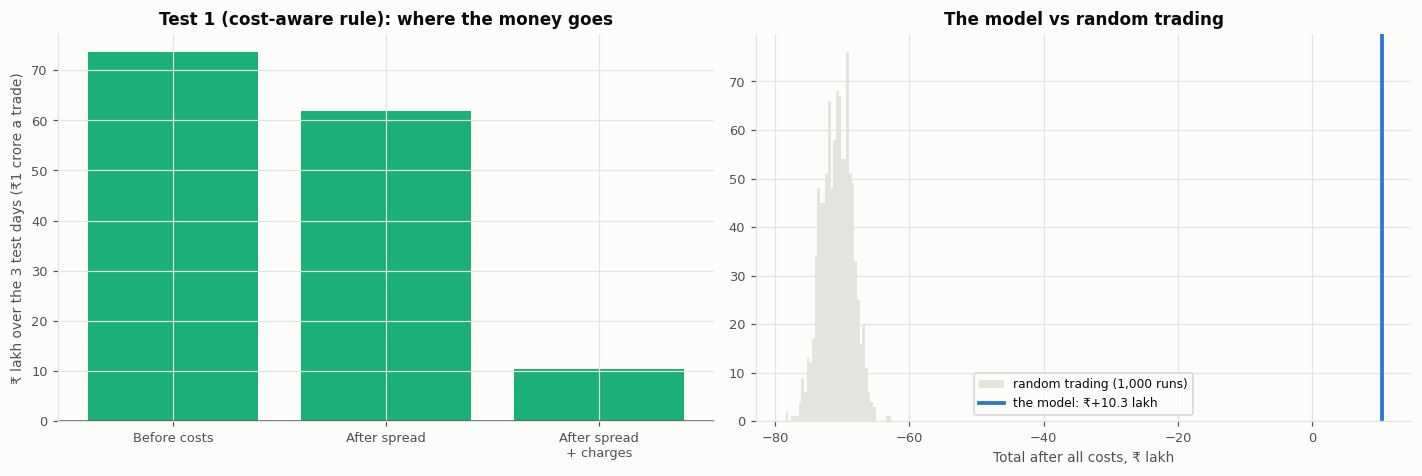

In [4]:
res = cost_aware(test, MARGIN)
res_old = fixed_cutoff(test, CUT)
steps = pd.DataFrame([{"Step": s, "Per trade (bps)": res[c].mean(), "Per trade (₹ per ₹1 crore)": rupees(res[c].mean()),
                       "Total over 3 test days (₹ lakh)": rupees(res[c].sum()) / 1e5}
                      for s, c in [("Before costs (move captured)", "Captured (bps)"), ("After the bid–ask spread", "After spread (bps)"),
                                   ("After spread and charges", "After charges (bps)")]])
print(f"Test days, cost-aware rule (margin {MARGIN:+.2f} bp): {len(res):,} trades ({len(res) / len(test):.1%} of moments)")
display(steps.style.format({"Per trade (bps)": "{:+.2f}", "Per trade (₹ per ₹1 crore)": "₹{:+,.0f}", "Total over 3 test days (₹ lakh)": "₹{:+.1f}"}).hide(axis="index"))
outcome = res.Outcome.value_counts(normalize=True).reindex(["Right way", "Wrong way", "No move"])
by_out = res.groupby("Outcome")["Captured (bps)"].mean().reindex(outcome.index)
print("How the trades landed:", ", ".join(f"{k} {v:.0%} (avg ₹{rupees(by_out[k]):+,.0f} before costs)" for k, v in outcome.items()))
by_day = res.groupby("Trading day").agg(Trades=("After charges (bps)", "size"), Net_bps=("After charges (bps)", "mean"),
                                         Total=("After charges (bps)", "sum"))
by_day["Net per trade (₹)"] = rupees(by_day.Net_bps); by_day["Total (₹ lakh)"] = rupees(by_day.Total) / 1e5
display(by_day[["Trades", "Net per trade (₹)", "Total (₹ lakh)"]].style.format({"Net per trade (₹)": "₹{:+,.0f}", "Total (₹ lakh)": "₹{:+.1f}"}))

rng = np.random.default_rng(SEED)
mv, spr = test["Actual move (bps)"].values, test["Spread (bps)"].values
luck = []
for _ in range(N_LUCK):
    idx = rng.choice(len(test), size=len(res), replace=False)
    side = rng.choice([-1, 1], size=len(res))
    luck.append((side * mv[idx] - spr[idx] - CHARGES_BPS).sum())
REAL = res["After charges (bps)"].sum()
P_LUCK = (1 + np.sum(np.array(luck) >= REAL)) / (N_LUCK + 1)
DAYS_POS = int((by_day.Total > 0).sum())
ENOUGH = bool(REAL > 0 and P_LUCK < 0.05 and DAYS_POS >= 2)
print(f"Luck check: random trading of {len(res):,} moments made ₹{rupees(np.mean(luck)) / 1e5:+.1f} lakh on average "
      f"(95% range ₹{rupees(np.percentile(luck, 2.5)) / 1e5:+.1f} to ₹{rupees(np.percentile(luck, 97.5)) / 1e5:+.1f} lakh); p = {P_LUCK:.4f}")
print(f"Enough economic value? {'Yes' if ENOUGH else 'No'} (net {'>' if REAL > 0 else '≤'} 0; p {P_LUCK:.4f}; positive days {DAYS_POS} of 3)")

# 95% range of the total (resampling the trades 1,000 times) and the result by stock
boot1 = [rng.choice(res["After charges (bps)"].values, size=len(res), replace=True).sum() for _ in range(N_LUCK)]
T1_LO, T1_HI = np.percentile(boot1, [2.5, 97.5])
print(f"95% range of the total after all costs: ₹{rupees(T1_LO) / 1e5:+.1f} to ₹{rupees(T1_HI) / 1e5:+.1f} lakh")
t1_stock = res.groupby("Stock").agg(Trades=("After charges (bps)", "size"), net=("After charges (bps)", "mean"), total=("After charges (bps)", "sum"),
                                     spread=("Spread (bps)", "mean"))
t1_stock = pd.DataFrame({"Trades": t1_stock.Trades, "Net per trade (₹)": rupees(t1_stock.net), "Total (₹ lakh)": rupees(t1_stock.total) / 1e5,
                         "Average spread paid (₹)": rupees(t1_stock.spread)})
print(f"By stock: profitable in {(t1_stock['Total (₹ lakh)'] > 0).sum()} of {len(t1_stock)} stocks")
display(t1_stock.style.format({"Net per trade (₹)": "₹{:+,.0f}", "Total (₹ lakh)": "₹{:+.1f}", "Average spread paid (₹)": "₹{:,.0f}"}))

compare = pd.DataFrame([summary_row(f"Cost-aware rule (margin {MARGIN:+.2f} bp)", res, len(test)),
                        summary_row(f"Old rule: fixed cut-off {CUT}", res_old, len(test))])
print("The two rules on the test days:")
display(compare.style.format(FMT_T, na_rep="—").hide(axis="index"))
near = pd.DataFrame([summary_row(f"Margin {m:+.2f} bp", cost_aware(test, m), len(test)) for m in (-0.25, 0.0, 0.25, 0.5, 1.0)])
print("Nearby margins on the test days:")
display(near.style.format(FMT_T, na_rep="—").hide(axis="index"))

MEANING = {2.5: "Only if the government cut the tax (STT alone is 2.5 bps): not realistic today",
           3.0: "Only with lower exchange charges or a tax cut: unlikely",
           3.5: "The base: statutory charges, zero brokerage, every order filled at the quoted price",
           4.0: "If brokerage or a slightly worse fill adds half a basis point",
           4.5: "If brokerage and worse fills add a full basis point"}
rows = []
for c in (2.5, 3.0, 3.5, 4.0, 4.5):
    knows, blind = cost_aware(test, MARGIN, rule_cost=c, real_cost=c), cost_aware(test, MARGIN, rule_cost=CHARGES_BPS, real_cost=c)
    rows.append({"Charges per round trip (bps)": c, "What it would mean": MEANING[c],
                 "If the rule knows the real cost: trades": len(knows), "…total (₹ lakh)": rupees(knows["After charges (bps)"].sum()) / 1e5,
                 "If the rule assumes 3.5 but the real cost is this: total (₹ lakh)": rupees(blind["After charges (bps)"].sum()) / 1e5})
sens = pd.DataFrame(rows)
print("Check: how the result depends on the charges assumed (3.5 bps is the base, decision M7-06):")
display(sens.style.format({"…total (₹ lakh)": "₹{:+.1f}", "If the rule assumes 3.5 but the real cost is this: total (₹ lakh)": "₹{:+.1f}"}).hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
labels = ["Before costs", "After spread", "After spread\n+ charges"]
vals = steps["Total over 3 test days (₹ lakh)"].values
ax.bar(labels, vals, color=[GAIN if v > 0 else LOSS for v in vals])
ax.axhline(0, color=INK_2, lw=1)
ax.set_ylabel("₹ lakh over the 3 test days (₹1 crore a trade)")
ax.set_title("Test 1 (cost-aware rule): where the money goes")
ax = axes[1]
ax.hist(rupees(np.array(luck)) / 1e5, bins=40, color=GRID, label="random trading (1,000 runs)")
ax.axvline(rupees(REAL) / 1e5, color=BLUE, lw=2.5, label=f"the model: ₹{rupees(REAL) / 1e5:+.1f} lakh")
ax.set_xlabel("Total after all costs, ₹ lakh"); ax.set_title("The model vs random trading"); ax.legend(fontsize=8)
fig.tight_layout(); save_chart(fig, "01_test1_trading"); plt.show()

## 4. Test 2: timing the desk's orders (decision M7-14)

**The rule:** every test moment is treated as a moment when the desk must place a **₹1 crore buy order**, and separately a **₹1 crore sell order**.
- **Buy order:** if the model leans towards a fall (lean < 0), **wait** 0.1 s and buy then; otherwise buy now.
- **Sell order:** if the model leans towards a rise (lean > 0), wait and sell then; otherwise sell now.
- **Saving** = how much better the price is after waiting: for a buy, the fall in price; for a sell, the rise. Orders placed now save nothing. No extra charges: the order is placed either way.

```text
Saving on a delayed buy  = −move × ₹1,000 per bp     (price fell → positive saving)
Saving on a delayed sell = +move × ₹1,000 per bp
```

**Assumptions:** the spread doesn't change during the wait, and the order is too small to move the price. Waits longer than 0.1 s, repeated waits and limit orders can't be tested (the data only shows the price 0.1 s ahead).

Orders delayed: 50%; delays that paid off: 69%
Average saving over ALL orders: 1.31 bps = ₹1,315 per ₹1 crore of orders
Luck check: random waiting saves ₹+0 on average (95% range ₹-30 to ₹+29); p = 0.0010
Average saving per ₹1 crore: Buy orders ₹1,332, Sell orders ₹1,298


,Saving (₹ per ₹1 crore),Typical spread (₹ per ₹1 crore)
Stock,,
NOVA01,"₹1,310","₹1,141"
NOVA02,"₹1,315",₹775
NOVA03,"₹1,275","₹2,308"
NOVA04,"₹1,357","₹1,426"
NOVA05,"₹1,233",₹646
NOVA06,"₹1,317","₹3,127"
NOVA07,"₹1,462",₹989
NOVA08,"₹1,369","₹1,730"
NOVA09,"₹1,256",₹461


Wrong delays: 31% of delays; they cost ₹3,223 on average (worst 5%: more than ₹8,353)
95% range of the average saving: ₹1,272 to ₹1,356 per ₹1 crore
Per ₹100 crore of orders a day: ₹1.31 lakh a day; ₹3.43 crore a year (261 trading days)
Waiting only when the lean is beyond 0.3: saves ₹1,119 per ₹1 crore across all orders
Waiting only when the lean is beyond 0.6: saves ₹396 per ₹1 crore across all orders
OBI alone used for timing: ₹1,287 per ₹1 crore


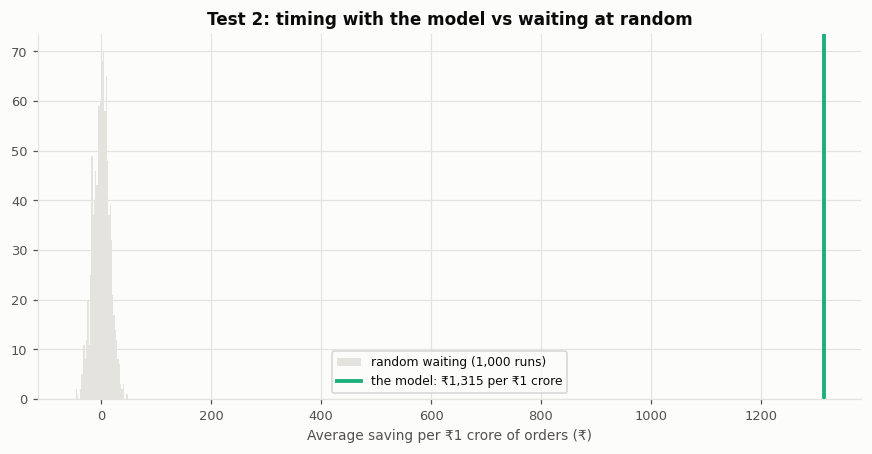

In [5]:
def timing(part: pd.DataFrame, lean_col: str = LEAN) -> pd.DataFrame:
    """One row per moment and side (buy, sell): wait or place now, and the saving in bps."""
    lean, mv_ = part[lean_col].values, part["Actual move (bps)"].values
    buy = pd.DataFrame({"Side": "Buy", "Stock": part.Stock.values, "Day": part["Trading day"].values,
                        "Wait": lean < 0, "Saving (bps)": np.where(lean < 0, -mv_, 0.0)})
    sell = pd.DataFrame({"Side": "Sell", "Stock": part.Stock.values, "Day": part["Trading day"].values,
                         "Wait": lean > 0, "Saving (bps)": np.where(lean > 0, mv_, 0.0)})
    return pd.concat([buy, sell], ignore_index=True)


T2 = timing(test)
SAVE = T2["Saving (bps)"].mean()
delayed = T2[T2.Wait]
print(f"Orders delayed: {T2.Wait.mean():.0%}; delays that paid off: {(delayed['Saving (bps)'] > 0).mean():.0%}")
print(f"Average saving over ALL orders: {SAVE:.2f} bps = ₹{rupees(SAVE):,.0f} per ₹1 crore of orders")

# Luck check: wait on the same share of orders, chosen at random
rng = np.random.default_rng(SEED + 1)
mv_all = np.concatenate([-test["Actual move (bps)"].values, test["Actual move (bps)"].values])   # saving if a buy / a sell waits
share = T2.Wait.mean()
luck2 = [np.where(rng.random(len(mv_all)) < share, mv_all, 0).mean() for _ in range(N_LUCK)]
P_LUCK2 = (1 + np.sum(np.array(luck2) >= SAVE)) / (N_LUCK + 1)
print(f"Luck check: random waiting saves ₹{rupees(np.mean(luck2)):+,.0f} on average (95% range ₹{rupees(np.percentile(luck2, 2.5)):+,.0f} "
      f"to ₹{rupees(np.percentile(luck2, 97.5)):+,.0f}); p = {P_LUCK2:.4f}")

# Buys vs sells, and by stock
sides = T2.groupby("Side")["Saving (bps)"].mean().apply(rupees)
print("Average saving per ₹1 crore:", ", ".join(f"{k} orders ₹{v:,.0f}" for k, v in sides.items()))
stock = T2.groupby("Stock").agg(saving=("Saving (bps)", "mean")).assign(**{"Saving (₹ per ₹1 crore)": lambda d: rupees(d.saving)})
stock["Typical spread (₹ per ₹1 crore)"] = test.groupby("Stock")["Spread (₹ per ₹1 crore)"].median()
display(stock[["Saving (₹ per ₹1 crore)", "Typical spread (₹ per ₹1 crore)"]].style.format("₹{:,.0f}"))

# Downside: wrong delays, and the 95% range of the average saving (resampling moments 1,000 times)
wrong = delayed[delayed["Saving (bps)"] < 0]["Saving (bps)"]
boot = [rng.choice(T2["Saving (bps)"].values, size=len(T2), replace=True).mean() for _ in range(N_LUCK)]
LO, HI = np.percentile(boot, [2.5, 97.5])
print(f"Wrong delays: {len(wrong) / len(delayed):.0%} of delays; they cost ₹{rupees(-wrong.mean()):,.0f} on average "
      f"(worst 5%: more than ₹{rupees(-wrong.quantile(0.05)):,.0f})")
print(f"95% range of the average saving: ₹{rupees(LO):,.0f} to ₹{rupees(HI):,.0f} per ₹1 crore")
per_day = SAVE / 1e4 * DESK_CRORE_A_DAY * 1e7
print(f"Per ₹{DESK_CRORE_A_DAY} crore of orders a day: ₹{per_day / 1e5:.2f} lakh a day; ₹{per_day * DAYS_A_YEAR / 1e7:.2f} crore a year ({DAYS_A_YEAR} trading days)")

# One line each (M7-14): stronger cut-offs, and OBI alone for timing
for c in (0.3, 0.6):
    lean = test[LEAN].values; mv_ = test["Actual move (bps)"].values
    s_c = np.concatenate([np.where(lean < -c, -mv_, 0), np.where(lean > c, mv_, 0)]).mean()
    print(f"Waiting only when the lean is beyond {c}: saves ₹{rupees(s_c):,.0f} per ₹1 crore across all orders")
print(f"OBI alone used for timing: ₹{rupees(timing(test, 'Lean: OBI alone')['Saving (bps)'].mean()):,.0f} per ₹1 crore")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(rupees(np.array(luck2)), bins=40, color=GRID, label="random waiting (1,000 runs)")
ax.axvline(rupees(SAVE), color=GAIN, lw=2.5, label=f"the model: ₹{rupees(SAVE):,.0f} per ₹1 crore")
ax.set_xlabel("Average saving per ₹1 crore of orders (₹)"); ax.set_title("Test 2: timing with the model vs waiting at random")
ax.legend(fontsize=8)
fig.tight_layout(); save_chart(fig, "02_test2_timing"); plt.show()

## 5. The recommendation (decision M7-12)

| Test 1 (trading) | Test 2 (timing) | Recommendation |
| --- | --- | --- |
| Loses after charges | Saves money | Don't run a standalone trading strategy; use the model to time the desk's orders |
| Profits after charges | Saves money | Both: selective trading and order timing |
| Loses | Saves nothing | The prediction is real but has no economic value at these costs |
| Profits | Saves nothing | Selective trading only |

In [6]:
TIMING_SAVES = bool(SAVE > 0 and P_LUCK2 < 0.05)
REC = {(False, True): "Don't run a standalone trading strategy at Indian intraday costs; use the model to time the desk's own orders",
       (True, True): "Both: time the desk's own orders now, and run the cost-aware trading rule as a measured pilot",
       (False, False): "The prediction is real but has no economic value at these costs",
       (True, False): "Selective trading only"}[(ENOUGH, TIMING_SAVES)]
print(f"Test 1 enough value: {ENOUGH}; Test 2 saves money: {TIMING_SAVES}")
print("Recommendation:", REC)

Test 1 enough value: True; Test 2 saves money: True
Recommendation: Both: time the desk's own orders now, and run the cost-aware trading rule as a measured pilot


## 5b. What goes to Module 9: HFT in the standard fields (decision M7-18)
Module 9 compares every business on the same fields. HFT is **not a place to park capital**: order timing improves orders NovaFin places anyway, and the trading pilot needs little money. So its fields are stated per ₹ of orders or trades, with the link to Module 9's own equity trading:
- **Order timing on the desk's orders:** saving per ₹ of orders (Test 2).
- **Order timing on Module 9's equity money:** Module 6's equal-weight portfolio trades about 6.5% of its value a month (≈ 0.8× a year), so the saving per ₹ of equities a year = turnover × saving per ₹ of orders.
- **Trading pilot:** profit per ₹ traded (Test 1), its 95% range, and the result if real costs are 1 bp higher (the bad case).

In [7]:
K6A = json.loads((PROJECT_ROOT / "module_06_portfolio_optimization" / "outputs" / "partA" / "key_numbers.json").read_text(encoding="utf-8"))
TURN = K6A["strategies"]["Equal weight"]["Turnover a month"] * 12                     # about 0.8 of the equity money traded a year
save_pct = rupees(SAVE) / 1e7 * 100                                                   # % of each ₹ of orders
net_trade_pct = rupees(res["After charges (bps)"].mean()) / 1e7 * 100                 # % of each ₹ traded, per trade
s45 = sens.set_index("Charges per round trip (bps)").loc[4.5]
m9_inputs = pd.DataFrame([
    {"Category": "High frequency trading: order timing (desk orders)", "What NovaFin would put money into": "Nothing extra: a model that times orders the desk places anyway",
     "Return per ₹ deployed (% a year)": "Saving of {:.3f}% of every ₹ of orders".format(save_pct),
     "Return range (% a year)": "{:.3f}% to {:.3f}% of orders (95% range)".format(rupees(LO) / 1e5, rupees(HI) / 1e5),
     "Bad-year result per ₹ (% a year)": "0 (waiting at random saves nothing; the model never adds cost)",
     "How the bad year is defined": "If the signal stopped working, waits would save nothing on average",
     "Capacity (₹ crore)": "Any order volume (orders assumed too small to move prices)", "Evidence strength": "Strong on 3 test days (p = 0.001; all 10 stocks), but only 0.1 s ahead",
     "How fast the money can come back": "No capital tied up", "Data gap or assumption": "NovaFin's real order volume is not in the data",
     "Controls": "Wait at most 0.1 s; switch off if savings turn negative", "Detail tab": "T2 trade decisions",
     "Detail column(s)": "Test 2: saving on the buy / sell (₹ per ₹1 crore)", "Decision": "M7-14, M7-18"},
    {"Category": "High frequency trading: order timing on Module 9's equity money", "What NovaFin would put money into": "Timing the equity allocation's own monthly trades",
     "Return per ₹ deployed (% a year)": round(TURN * save_pct, 4), "Return range (% a year)": "{:.4f} to {:.4f}".format(TURN * rupees(LO) / 1e5, TURN * rupees(HI) / 1e5),
     "Bad-year result per ₹ (% a year)": 0.0, "How the bad year is defined": "Signal stops working: no saving",
     "Capacity (₹ crore)": "Scales with the equity allocation", "Evidence strength": "As above; turnover measured in Module 6",
     "How fast the money can come back": "No capital tied up", "Data gap or assumption": "Equal-weight turnover ≈ 0.8× a year (Module 6)",
     "Controls": "As above", "Detail tab": "T2 trade decisions", "Detail column(s)": "Test 2 saving; Module 6 turnover", "Decision": "M7-18"},
    {"Category": "High frequency trading: trading pilot", "What NovaFin would put money into": "Trading on the signal with the cost-aware rule, ₹1 crore a trade",
     "Return per ₹ deployed (% a year)": "{:+.3f}% of each ₹ traded, per trade (+₹{:,.0f} per ₹1 crore)".format(net_trade_pct, rupees(res["After charges (bps)"].mean())),
     "Return range (% a year)": "₹{:+.1f} to ₹{:+.1f} lakh over 3 test days (95% range)".format(rupees(T1_LO) / 1e5, rupees(T1_HI) / 1e5),
     "Bad-year result per ₹ (% a year)": "₹{:+.1f} lakh over 3 test days if real costs are 1 bp higher and the rule isn't told".format(s45["If the rule assumes 3.5 but the real cost is this: total (₹ lakh)"]),
     "How the bad year is defined": "Real trading costs 1 bp above the 3.5 bps assumed (brokerage, worse fills)",
     "Capacity (₹ crore)": "Small: a pilot; positions last 0.1 s", "Evidence strength": "3 test days; profitable every day, 8 of 10 stocks, p = 0.001; costs assumed",
     "How fast the money can come back": "Same day (no overnight positions)", "Data gap or assumption": "Brokerage, slippage and fills not in the data",
     "Controls": "Measured pilot: narrow-spread stocks first; record real costs; feed them into the rule; stop if net turns negative",
     "Detail tab": "T2 trade decisions", "Detail column(s)": "Test 1: after spread and charges (₹ per ₹1 crore)", "Decision": "M7-13, M7-15, M7-18"}])
display(m9_inputs[["Category", "Return per ₹ deployed (% a year)", "Bad-year result per ₹ (% a year)"]])
print(f"On Module 9's equity money, order timing is worth about {TURN * save_pct:.3f}% a year (₹{TURN * rupees(SAVE) * 100 / 1e5:.2f} lakh per ₹100 crore of equities): real, but too small to change an allocation.")

,Category,Return per ₹ deployed (% a year),Bad-year result per ₹ (% a year)
0,High frequency trading: order timing (desk ord...,Saving of 0.013% of every ₹ of orders,0 (waiting at random saves nothing; the model ...
1,High frequency trading: order timing on Module...,0.0103,0.0
2,High frequency trading: trading pilot,"+0.007% of each ₹ traded, per trade (+₹700 per...",₹-4.4 lakh over 3 test days if real costs are ...


On Module 9's equity money, order timing is worth about 0.010% a year (₹1.03 lakh per ₹100 crore of equities): real, but too small to change an allocation.


## 6. What the results say

**In one sentence: the prediction is worth money in both uses. Timing the desk's own orders saves about ₹1,300 per ₹1 crore of orders. Trading on the signal, using the cost-aware rule that Task 1's results point to, makes about ₹700 per ₹1 crore trade, on every test day.**

All money figures are per **₹1 crore** traded (a measuring unit; 1 bp = ₹1,000), on the 3 test days (28–30 Jan 2026), with logistic regression from Task 1.

### How Task 1's results shaped Test 1 (decisions M7-13, M7-17)
Task 1 (its step 7) found three things:
1. the move a trade catches grows in step with the model's lean, about 7.1 bps × the lean;
2. the percentages are honest;
3. spreads are widest when the model is most confident.

**So the first rule, "trade whenever the lean is beyond 0.70", traded exactly where costs were highest:** an average spread of ₹2,203 per trade. **The revised rule** trades only when the **expected gain (7.1 bps × the lean) beats that moment's own cost**, meaning its spread + 3.5 bps of charges. The margin was chosen on the tuning days: 0, which made the most total profit.

### Test 1: trading on the signal

| Rule, test days | Trades | Net per trade | Total over 3 days | Average spread paid |
| --- | --- | --- | --- | --- |
| **Cost-aware rule (revised)** | **1,473 (8.2% of moments)** | **+₹700** | **+₹10.3 lakh** | ₹794 |
| Old rule: fixed cut-off 0.70 | 868 (4.9%) | +₹516 | +₹4.5 lakh | ₹2,203 |

**Where the money goes (cost-aware rule, per trade):** +₹4,994 before costs → +₹4,200 after the spread → **+₹700 after charges**. That means 86% of the gross gain goes on costs.

- **How the trades landed:**
  - right way: 78% (about +₹6,980 each before costs);
  - wrong way: 12% (about −₹3,790);
  - no move: 11% (about ₹0, but still paying the costs).
- **Every test day is positive:** +₹1.6 lakh, +₹5.2 lakh and +₹3.5 lakh.
- **How sure:** the 95% range of the total is **+₹6.4 to +₹14.1 lakh**, entirely above zero.
- **Beyond luck:** trading the same number of random moments in random directions loses about ₹71 lakh, and all 1,000 runs lose (p = 0.001).
- **By stock: profitable in 8 of 10.**
  - **The most profit is where spreads are narrowest.** NOVA09 (typical spread ₹461) made +₹4.7 lakh from 420 trades.
  - **The two exceptions are wide-spread stocks the rule rarely trades:** NOVA03 (21 trades, −₹0.4 lakh) and NOVA06 (1 trade).
- **Nearby margins also profit:** from +₹2.1 lakh (demanding 1 bp extra) to +₹13.0 lakh (accepting 0.25 bp less).

**How much it depends on the cost per trade.** The statutory part is fixed by law and the exchange. Brokerage and a worse price than quoted (slippage) were assumed zero, so they can only add cost.

| Cost per round trip | What it would mean | If the rule knows the real cost | If the rule assumes 3.5 but the real cost is this |
| --- | --- | --- | --- |
| 2.5 bps | Only if the government cut the tax (STT alone is 2.5): not realistic today | +₹43.6 lakh (4,620 trades) | +₹25.0 lakh |
| 3.0 bps | Only with lower exchange charges or a tax cut: unlikely | +₹25.8 lakh | +₹17.7 lakh |
| **3.5 bps (base)** | **Statutory charges, zero brokerage, fills at the quoted price** | **+₹10.3 lakh** | **+₹10.3 lakh** |
| 4.0 bps | Brokerage or a slightly worse fill adds half a basis point | +₹3.0 lakh (572 trades) | +₹2.9 lakh |
| 4.5 bps | Brokerage and worse fills add a full basis point | +₹0.7 lakh (138 trades) | −₹4.4 lakh |

- **When the rule is given the real cost, it protects itself:** it trades less and stays profitable even at 4.5 bps.
- **If the real cost is underestimated by 1 bp, it loses money.** So measuring the true cost matters most.
- **Verdict (decision M7-15): enough economic value.** It is profitable after all costs, beyond luck, positive on all 3 days, and its range sits above zero. But it is modest: about 14% of the gross gain survives the costs.

### Test 2: timing orders the desk must place anyway
For every test moment, imagine the desk must buy (and, separately, sell) ₹1 crore. When the model expects the price to move against the order, it waits a tenth of a second. There are no extra charges, because the order happens either way.

- **It saves ₹1,315 per ₹1 crore of orders on average** (95% range ₹1,272–₹1,356).
  - Buys save ₹1,332 and sells ₹1,298; each of the 10 stocks saves ₹1,233–₹1,462.
  - Waiting at random saves ₹0 (p = 0.001).
- **Half the orders wait, and 69% of those waits pay off.** The 31% that go wrong cost ₹3,223 on average.
- **In ₹ for the desk:** per ₹100 crore of orders a day, about **₹1.31 lakh a day, ₹3.43 crore a year** (261 trading days).
- **Other versions:**
  - waiting only on strong signals saves less in total: ₹1,119 beyond a lean of 0.3, ₹396 beyond 0.6;
  - the simple buyer/seller balance alone does almost as well: ₹1,287.
- **Limits:** the data shows the price only 0.1 s ahead; the spread is assumed not to change during the wait; orders are assumed too small to move the price.

### The recommendation (decision M7-12): what it means, what it adds, why it matters

**It answers the Head of Trading's two-part question** ("predict short-horizon price movements **and improve order execution**") and the brief's "does the prediction generate enough economic value?". It turns the analysis into what to do, and what each part is worth.

**1. Time the desk's own orders now.**
- **What it means:** the desk already places large client orders every day. When it has to buy, it checks the model first. If the model expects the price to dip in the next tenth of a second, it waits a moment and buys a little cheaper (the reverse for sales).
- **What it adds:** about **₹1,315 saved for every ₹1 crore of orders**, which is about **₹1.3 lakh a day, ₹3.4 crore a year** for a desk placing ₹100 crore of orders a day. It grows with the desk's volume.
- **Why now:** there's no extra cost (the order and its taxes happen anyway), it's reliable (buys and sells, all 10 stocks, far beyond luck), and it's low-risk (it changes only *when* an order goes in, not *whether*).

**2. Run the cost-aware trading rule as a measured pilot.**
- **What it means:** NovaFin could also trade for its own profit, buying and selling within a tenth of a second when the expected gain beats that moment's cost. On the test days this made **+₹700 per ₹1 crore trade, +₹10.3 lakh over 3 days, profitable every day**.
- **Why a pilot, not full scale:**
  - The margin is thin. Of ₹4,994 caught per trade before costs, ₹4,294 (86%) went on the spread and taxes.
  - It rests on costs that were assumed, not measured (zero brokerage, fills at the quoted price). If the real cost is 1 bp higher and the rule isn't told, the ₹10.3 lakh becomes a ₹4.4 lakh loss.
- **The pilot, step by step:**
  1. Start with small trades in the narrow-spread stocks, where most of the profit came from (NOVA09: +₹4.7 lakh).
  2. Record the real brokerage, the prices actually achieved and the slippage.
  3. Feed the real cost into the rule. Told the true cost, it trades less and stayed profitable even at 1 bp more (+₹0.7 lakh).
  4. Stop if the profit after costs turns negative.
- **What it adds:** a chance at extra trading income, with the true costs found out before real money is committed.

**Why it matters for the Board and Module 9**

| Without the recommendation | With it |
| --- | --- |
| "The model is 60.6% accurate", which says nothing about money | Two concrete uses, each with a ₹ value and a risk level |
| Risk of funding a trading desk on a thin, cost-sensitive profit | Capital goes only where the gain is solid (order timing); trading earns its place through a pilot |
| Module 9 can't value high-frequency trading | Module 9 gets ₹1,315 saved per ₹1 crore of orders as a cost saving, and trading as a small pilot rather than a capital line |

**In short:** the model's value lies mainly in making the desk's existing trading cheaper, which is dependable and should start now. Trading on it for profit may add more, but only after its real costs are proven.

## 7. Save the outputs

- **`FINAL_M7_T2_trade_decisions.csv`: the Task 2 final file** (decision M7-16). One row per test-day moment: the model's chances and lean; **Test 1**: trade or not, buy or sell, the move captured, after spread, after charges, in ₹; **Test 2**: for a buy order and a sell order, wait or place now, and the saving in ₹; and the **reasons in plain words**.
- `test1_rules.csv` (the tuning-day sweeps for the cost-aware rule and the old cut-off rule), the charts and `key_numbers.json`.

In [8]:
out = test[["Trading day", "Time", "Stock", "Mid price (₹)", "Chance of UP", "Chance of DOWN", "Chance of NO_MOVE", LEAN, "Actual",
            "Actual move (bps)", "Spread (bps)"]].copy()
lean, mv_, spr_ = out[LEAN].values, out["Actual move (bps)"].values, out["Spread (bps)"].values
edge = expected_edge(out)
trade = (edge > MARGIN).values
out["Test 1: expected gain (₹ per ₹1 crore)"] = rupees(SLOPE * np.abs(lean))
out["Test 1: this moment's cost (₹ per ₹1 crore)"] = rupees(spr_ + CHARGES_BPS)
out["Test 1: trade"] = np.where(trade, np.where(lean > 0, "Buy", "Sell"), "No trade")
cap = np.where(trade, np.sign(lean) * mv_, 0.0)
out["Test 1: move captured (₹ per ₹1 crore)"] = rupees(cap)
out["Test 1: after spread (₹ per ₹1 crore)"] = np.where(trade, rupees(cap - spr_), 0.0)
out["Test 1: after spread and charges (₹ per ₹1 crore)"] = np.where(trade, rupees(cap - spr_ - CHARGES_BPS), 0.0)
out["Test 2: a buy order would"] = np.where(lean < 0, "Wait 0.1 s", "Buy now")
out["Test 2: saving on the buy (₹ per ₹1 crore)"] = np.where(lean < 0, rupees(-mv_), 0.0)
out["Test 2: a sell order would"] = np.where(lean > 0, "Wait 0.1 s", "Sell now")
out["Test 2: saving on the sell (₹ per ₹1 crore)"] = np.where(lean > 0, rupees(mv_), 0.0)


def moved(m):
    return f"rose {m / 100:.3f}%" if m > 1.2 else (f"fell {-m / 100:.3f}%" if m < -1.2 else "didn't move")


def reason_test1(u, d, l, m, s, t, net):
    cost = rupees(s) + rupees(CHARGES_BPS)
    expect = rupees(SLOPE * abs(l))
    if t == "No trade":
        return (f"The model's lean ({u:.0%} chance of a rise vs {d:.0%} of a fall) suggests about ₹{expect:,.0f} per ₹1 crore, "
                f"less than this moment's cost of about ₹{cost:,.0f} (spread ₹{rupees(s):,.0f} + charges ₹{rupees(CHARGES_BPS):,.0f}), so no trade.")
    action = "buy ₹1 crore and sell a tenth of a second later" if t == "Buy" else "sell ₹1 crore and buy back a tenth of a second later"
    return (f"The model expects about ₹{expect:,.0f} per ₹1 crore ({u:.0%} chance of a rise vs {d:.0%} of a fall), more than this moment's cost "
            f"of about ₹{cost:,.0f}, so {action}. "
            f"The price {moved(m)}: worth ₹{rupees(np.sign(l) * m):+,.0f}; the bid–ask gap cost ₹{rupees(s):,.0f} and charges ₹{rupees(CHARGES_BPS):,.0f}, "
            f"leaving ₹{net:+,.0f}.")


def reason_test2(l, m):
    if l < 0:
        return (f"The model expects a fall, so a buy order waits a tenth of a second (the price {moved(m)}, saving ₹{rupees(-m):+,.0f} per ₹1 crore) "
                f"and a sell order goes now.")
    return (f"The model expects a rise, so a buy order goes now and a sell order waits a tenth of a second (the price {moved(m)}, "
            f"saving ₹{rupees(m):+,.0f} per ₹1 crore on the sale).")


out["Test 1: reason in words"] = [reason_test1(u, d, l, m, s, t, n) for u, d, l, m, s, t, n in zip(
    out["Chance of UP"], out["Chance of DOWN"], lean, mv_, spr_, out["Test 1: trade"], out["Test 1: after spread and charges (₹ per ₹1 crore)"])]
out["Test 2: reason in words"] = [reason_test2(l, m) for l, m in zip(lean, mv_)]
save_table(out.round(4), "FINAL_M7_T2_trade_decisions")
save_table(pd.concat([sweep.drop(columns="Margin"), old.drop(columns="Cut-off")], ignore_index=True).round(4), "test1_rules")
print(out.loc[out["Test 1: trade"] != "No trade", "Test 1: reason in words"].iloc[0])
print(out["Test 2: reason in words"].iloc[0])


def r4(v):
    return None if v is None or pd.isna(v) else round(float(v), 4)


key = {"model": MODEL, "rule": "cost-aware", "slope_bps_per_lean": r4(SLOPE), "margin_bps": MARGIN, "old_rule_cutoff": CUT,
       "old_rule_test": {"trades": len(res_old), "per_trade_rupees": r4(rupees(res_old["After charges (bps)"].mean())),
                         "total_lakh": r4(rupees(res_old["After charges (bps)"].sum()) / 1e5)}, "charges_bps": CHARGES_BPS,
       "test1": {"trades": len(res), "share": r4(len(res) / len(test)),
                 "per_trade_rupees": {s: r4(v) for s, v in zip(steps.Step, steps["Per trade (₹ per ₹1 crore)"])},
                 "total_lakh": {s: r4(v) for s, v in zip(steps.Step, steps["Total over 3 test days (₹ lakh)"])},
                 "outcome_shares": {k: r4(v) for k, v in outcome.items()}, "p_luck": r4(P_LUCK), "days_positive": DAYS_POS, "enough_value": ENOUGH,
                 "total_range_lakh": [r4(rupees(T1_LO) / 1e5), r4(rupees(T1_HI) / 1e5)],
                 "stocks_profitable": int((t1_stock["Total (₹ lakh)"] > 0).sum()),
                 "avg_spread_paid": r4(rupees(res["Spread (bps)"].mean())),
                 "charges_sensitivity_total_lakh": {str(r["Charges per round trip (bps)"]): [r4(r["…total (₹ lakh)"]),
                                                    r4(r["If the rule assumes 3.5 but the real cost is this: total (₹ lakh)"])] for _, r in sens.iterrows()}},
       "test2": {"saving_rupees_per_crore": r4(rupees(SAVE)), "range": [r4(rupees(LO)), r4(rupees(HI))], "p_luck": r4(P_LUCK2),
                 "share_delayed": r4(T2.Wait.mean()), "delays_paid": r4((delayed["Saving (bps)"] > 0).mean()),
                 "per_100cr_day_lakh": r4(per_day / 1e5), "per_100cr_day_year_crore": r4(per_day * DAYS_A_YEAR / 1e7),
                 "buy": r4(sides.get("Buy")), "sell": r4(sides.get("Sell")), "wrong_delay_cost": r4(rupees(-wrong.mean()))},
       "recommendation": REC}
key["module9"] = {"equity_turnover_year": r4(TURN), "timing_on_equity_pct_year": r4(TURN * save_pct)}
save_table(m9_inputs, "module9_inputs")                                          # the standard Module 9 fields (step 5b)
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1, ensure_ascii=False), encoding="utf-8")
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix()); print(sorted(p.name for p in OUT_DIR.iterdir()))

The model expects about ₹4,198 per ₹1 crore (14% chance of a rise vs 73% of a fall), more than this moment's cost of about ₹4,150, so sell ₹1 crore and buy back a tenth of a second later. The price fell 0.033%: worth ₹+3,252; the bid–ask gap cost ₹650 and charges ₹3,500, leaving ₹-898.
The model expects a fall, so a buy order waits a tenth of a second (the price fell 0.117%, saving ₹+11,750 per ₹1 crore) and a sell order goes now.
Saved to module_07_hft/outputs/task2
['01_test1_trading.png', '02_test2_timing.png', 'FINAL_M7_T2_trade_decisions.csv', 'key_numbers.json', 'module9_inputs.csv', 'test1_rules.csv']
